In [1]:
# Move to project directory
import os
os.chdir("/home/mdarif/MLOPS/customer-churn-prediction-system")
print(os.getcwd())

/home/mdarif/MLOPS/customer-churn-prediction-system


# Table of Content

**1. Introduction**

**2. Experiment Setup**
- 2.1 Importing Libraries
- 2.2 Project Configuration
- 2.3 MLflow and DagsHub Setup
- 2.4 Loading Dataset

**3. Data Preparation**
- 3.1 Duplicate Check
- 3.2 Preparing Features and Target
- 3.3 Encoding Categorical Features
- 3.4 Train-Test Split
- 3.5 Cross-Validation Strategy

**4. Baseline Model**
- 4.1 Baseline Model
- 4.2 Baseline Evaluation

**5. Model Experimentation**
- 5.1 Model Definitions
- 5.2 Hyperparameter Search Strategy
- 5.3 Model Training
- 5.4 Model Comparison
- 5.5 Model Ranking
- 5.6 Model Selection

**6. Hyperparameter Optimization**
- 6.1 RandomizedSearchCV
- 6.2 Optuna (TPE Bayesian Optimization)
- 6.3 Train Models from Each Optimization Method
- 6.4 Generate Test Predictions
- 6.5 Optimization Method Comparison
- 6.6 Select Optimization Method
- 6.7 Set the Final Parameters

**7. Final Model Evaluation**
- 7.1 Final Model
- 7.2 Classification Metrics
- 7.3 MLflow Helper Functions
- 7.4 Confusion Matrix
- 7.5 ROC Curve
- 7.6 Classification Threshold Analysis (out-of-fold, not test-set)
- 7.7 Cost-Based Threshold Selection
- 7.8 Feature Importance
- 7.9 Error Analysis

**8. MLflow Experiment Tracking**
- 8.1 Final Model Logging

**9. Conclusion**

## 1. Introduction

This notebook picks up after the EDA and covers the actual modeling part trying out a few classifiers tuning the best one checking how it performs and logging the whole thing to MLflow.

The main goal here is catching customers who are about to churn. Missing a
churner costs more than wrongly flagging a loyal customer, so Recall is the metric we're optimizing for not Accuracy.

Five models get compared: KNN, Logistic Regression, SVC, Decision Tree, and Random Forest.

## 2. Experiment Setup

### 2.1 Importing Libraries

In [2]:
# Import required libraries
import multiprocessing
import dagshub
import mlflow
import numpy as np
import optuna
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tempfile
from dotenv import load_dotenv
from tqdm import tqdm
from math import prod
from kaggle.api.kaggle_api_extended import KaggleApi
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
    cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)
from sklearn.inspection import permutation_importance
from mlflow.models import infer_signature

In [3]:
# Load environment variables
load_dotenv()

True

### 2.2 Project Configuration

In [4]:
# Set training configuration
total_cores = multiprocessing.cpu_count()
ENV = os.getenv("ENV", "development")

if ENV == "production":
  N_JOBS = 2
  N_ITER = 30
  CV_FOLDS = 5
else:
  N_JOBS = max(1, total_cores // 3)
  N_ITER = 10
  CV_FOLDS = 3

print(f"Environment: {ENV}")
print(f"Total cores: {total_cores}")
print(f"n_jobs: {N_JOBS}")
print(f"n_iter: {N_ITER}")
print(f"cv: {CV_FOLDS}")

Environment: development
Total cores: 12
n_jobs: 4
n_iter: 10
cv: 3


### 2.3 MLflow and DagsHub Setup


In [5]:
# Connect MLflow tracking with DagsHub
dagshub.init(
    repo_owner="TechArif",
    repo_name="customer-churn-prediction-system",
    mlflow=True
)

mlflow.set_experiment("Customer Churn Prediction")

Accessing as TechArif

Initialized MLflow to track repo "TechArif/customer-churn-prediction-system"

Repository TechArif/customer-churn-prediction-system initialized!

<Experiment: artifact_location='mlflow-artifacts:/0a796d7408dc46f38f1fd1de962f3781', creation_time=1789568785838, experiment_id='0', last_update_time=1789568785838, lifecycle_stage='active', name='Customer Churn Prediction', tags={}>

### 2.4 Loading Dataset

In [6]:
# Download dataset from kaggle
kaggle_username = os.getenv("KAGGLE_USERNAME")
kaggle_api_token = os.getenv("KAGGLE_API_TOKEN")

if not kaggle_username or not kaggle_api_token:
  raise ValueError("KAGGLE_USERNAME and KAGGLE_API_TOKEN must be set.")

api = KaggleApi()
api.authenticate()

dataset = "blastchar/telco-customer-churn"
download_dir = "/tmp/customer_churn"
os.makedirs(download_dir, exist_ok=True)

api.dataset_download_files(
  dataset=dataset,
  path=download_dir,
  unzip=True
)

file_path = os.path.join(
  download_dir,
  "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print(file_path)

Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
/tmp/customer_churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [7]:
# Load the dataset and display the first five rows
df = pd.read_csv(file_path)
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


## 3. Data Preparation

### 3.1 Duplicate Check

In [8]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()
duplicate_rows = df[df.duplicated(keep=False)]

print(f"Duplicate rows: {duplicate_count}")
print(duplicate_rows)

Duplicate rows: 0
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

[0 rows x 21 columns]


In [9]:
# Check duplicate features for different target values
feature_columns = df.columns.drop("Churn")

duplicate_features = df[
    df.duplicated(subset=feature_columns, keep=False)
].sort_values(by=list(feature_columns))

target_counts = (
    duplicate_features.groupby(list(feature_columns))["Churn"].nunique()
)

conflicting_duplicates = target_counts[target_counts > 1]
print(f"Conflicting duplicate groups: {len(conflicting_duplicates)}")

Conflicting duplicate groups: 0


### Observation

The dataset contains 0 duplicate rows. No conflicting duplicate groups were found, so identical feature values do not have different `churn`targets.

### 3.2 Preparation Features and Target

Dropping `customerID` since it's just an identifier and won't help the model learn anything.
Target variable is `Churn`.

In [10]:
# Remove the customer identifier
df = df.drop(columns=["customerID"])
print(f"Dataset shape: {df.shape}")

Dataset shape: (7043, 20)


In [11]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

TotalCharges data type: float64
Missing TotalCharges: 11


In [12]:
# Fill missing TotalCharges with the median
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
print(f"Missing values after filling: {df['TotalCharges'].isna().sum()}")

Missing values after filling: 0


In [13]:
# Separate features and target
X_raw = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Target values:", y.value_counts())
print("\nTarget data type:", y.dtype)

Target values: Churn
0    5174
1    1869
Name: count, dtype: int64

Target data type: int64


### Observation

The dataset has 5,174 non-chrun customers and 1,869 churn customers. The classes are imbalanced so accuracy alone is not enough for this problem. Recall is used as the main metric because we want to identify churn customers. 

### 3.3 Encoding Categorical Features

In [14]:
# Identify categorical features
categorical_columns = X_raw.select_dtypes(include="object").columns.tolist()

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:
# One-hot encode categorical features
X = pd.get_dummies(X_raw, columns=categorical_columns, drop_first=True, dtype=int)
print(f"Encoded feature shape: {X.shape}")

Encoded feature shape: (7043, 30)


### 3.4 Train-Test Split

In [16]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


In [17]:
# Verify class distribution after splitting
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Test target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


### 3.5 Cross-Validation Strategy

In [18]:
# Create stratified cross-validation strategy
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)
print(f"Cross-validation strategy: StratifiedKFold({CV_FOLDS})")

Cross-validation strategy: StratifiedKFold(3)


## 4. Baseline Model

### 4.1 Baseline Model

Before trying any real models, it's worth having a dumb baseline to compare against a majority-class classifier just predicts "no churn" for everyone if a real model can't beat this by a wide margin something's wrong.

In [19]:
# Create the baseline model
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

DummyClassifier(strategy='most_frequent')

### 4.2 Baseline Evaluation

In [20]:
# Generate baseline predictions
baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(y_test, baseline_pred, zero_division=0)
baseline_recall = recall_score(y_test, baseline_pred, zero_division=0)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Precision: {baseline_precision:.4f}")
print(f"Baseline Recall: {baseline_recall:.4f}")
print(f"Baseline F1: {baseline_f1:.4f}")

Baseline Accuracy: 0.7346
Baseline Precision: 0.0000
Baseline Recall: 0.0000
Baseline F1: 0.0000


### observation

The baseline gets 73.46 accuracy by predicting every customer as non-churn. But it detects none of the actual churn customers so Precision, Recall and F1 are all 0. This shows why accuracy alone is not enough here.

## 5. Model Experimentation

### 5.1 Model Definitions

Five classifiers models compared: `KNN`, `Logistic Regression`, `SVC`, `DecisionTree`, `Random Forest`

KNN/Logistic Regression/SVC get scaled inside a pipeline since they're distance/gradient based the tree models don't need it.

In [21]:
# Define models and hyperparameter search spaces
models = {
    "KNN": {
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=15))
        ]),
        "params": {
            "model__n_neighbors": list(range(3, 51)),
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    },
    "LogisticRegression": {
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=42))
        ]),
        "params": {
            "model__C": [0.01, 0.1, 1, 10, 100],
            "model__solver": ["lbfgs", "liblinear"],
            "model__class_weight": [None, "balanced"]
        }
    },
    "SVC": {
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(probability=True, random_state=42))
        ]),
        "params": {
            "model__C": [0.1, 1, 10, 100],
            "model__kernel": ["rbf"],
            "model__gamma": ["scale", "auto"],
            "model__class_weight": [None, "balanced"]
        }
    },
    "DecisionTree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {
            "max_depth": list(range(3, 16)),
            "min_samples_split": list(range(2, 21)),
            "min_samples_leaf": list(range(1, 9)),
            "criterion": ["gini", "entropy"],
            "class_weight": [None, "balanced"]
        }
    },
    "RandomForest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "n_estimators": list(range(100, 301, 50)),
            "max_depth": list(range(5, 16)),
            "min_samples_split": list(range(2, 21)),
            "min_samples_leaf": list(range(1, 9)),
            "max_features": ["sqrt", "log2"],
            "class_weight": [None, "balanced", "balanced_subsample"]
        }
    }
}

### 5.2 Hyperparameter Search Strategy

In [22]:
# Set the maximum search space size for GridSearchCV
SEARCH_SPACE_LIMIT = 200

In [23]:
# Calculate the number of hyperparameter combinations
for name, config in models.items():
    total_combinations = prod(len(values) for values in config["params"].values())
    print(f"{name}: {total_combinations} combinations")

KNN: 192 combinations
LogisticRegression: 20 combinations
SVC: 16 combinations
DecisionTree: 7904 combinations
RandomForest: 50160 combinations


### 5.3 Model Training

In [24]:
# Store model evaluation results and fitted models
results = []
trained_models = {}

In [25]:
# Train and evaluate all models
for name, config in tqdm(models.items(), desc="Training Models", leave=True, ncols=100):

    model = config["model"]
    params = config["params"]

    # Run hyperparameter search
    if params:
        total_combinations = prod(len(values) for values in params.values())

        # Select hyperparameter search strategy
        if total_combinations <= SEARCH_SPACE_LIMIT:
            search = GridSearchCV(
                estimator=model,
                param_grid=params,
                cv=CV,
                scoring="recall",
                n_jobs=N_JOBS,
                refit=True,
                verbose=0
            )
            search_type = "GridSearchCV"
        else:
            search = RandomizedSearchCV(
                estimator=model,
                param_distributions=params,
                n_iter=N_ITER,
                cv=CV,
                scoring="recall",
                n_jobs=N_JOBS,
                random_state=42,
                refit=True,
                verbose=0
            )
            search_type = "RandomizedSearchCV"

    else:
        search = model
        search_type = "No Hyperparameter Search"

    # Train and tune the model
    search.fit(X_train, y_train)

    best_model_current = search.best_estimator_ if params else search
    best_params_current = search.best_params_ if params else {}
    cv_recall = search.best_score_ if params else None

    # Store fitted model
    trained_models[name] = best_model_current

    # Training predictions
    y_train_pred = best_model_current.predict(X_train)

    # Training metrics
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_precision = precision_score(y_train, y_train_pred, zero_division=0)
    train_recall = recall_score(y_train, y_train_pred, zero_division=0)
    train_f1 = f1_score(y_train, y_train_pred, zero_division=0)

    # Test predictions
    y_test_pred = best_model_current.predict(X_test)

    # Test metrics
    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_precision = precision_score(y_test, y_test_pred, zero_division=0)
    test_recall = recall_score(y_test, y_test_pred, zero_division=0)
    test_f1 = f1_score(y_test, y_test_pred, zero_division=0)

    # ROC-AUC
    y_test_proba_current =(
        best_model_current.predict_proba(X_test)[:, 1]
        if hasattr(best_model_current, "predict_proba") else y_test_pred
    )
    test_roc_auc = roc_auc_score(y_test, y_test_proba_current)

    # Overfitting check
    recall_gap = train_recall - test_recall

    # Log experiments to MLflow
    with mlflow.start_run(run_name=name):

        # Log hyperparameter search details to MLflow
        mlflow.log_param("search_method", search_type)
        mlflow.log_param("cv_strategy", "StratifiedKFold")
        mlflow.log_param("cv_folds", CV_FOLDS)
        mlflow.log_param("scoring", "recall")
        if params:
            mlflow.log_param("total_combinations", total_combinations)
        if search_type == "RandomizedSearchCV":
            mlflow.log_param("n_iter", N_ITER)
        mlflow.log_params(best_params_current)

        # Log model performance metrics to MLflow
        mlflow.log_metric("CV_Recall", cv_recall)
        mlflow.log_metric("Train_Accuracy", train_accuracy)
        mlflow.log_metric("Test_Accuracy", test_accuracy)
        mlflow.log_metric("Train_Precision", train_precision)
        mlflow.log_metric("Test_Precision", test_precision)
        mlflow.log_metric("Train_Recall", train_recall)
        mlflow.log_metric("Test_Recall", test_recall)
        mlflow.log_metric("Recall_Gap", recall_gap)
        mlflow.log_metric("Train_F1", train_f1)
        mlflow.log_metric("Test_F1", test_f1)
        mlflow.log_metric("Test_ROC_AUC", test_roc_auc)

        # Store results for model comparison
        results.append({
            "Model": name,
            "Search_Method": search_type,
            "CV_Recall": round(cv_recall, 4) if cv_recall is not None else None,
            "Best_Params": best_params_current,
            "Train_Accuracy": round(train_accuracy, 4),
            "Test_Accuracy": round(test_accuracy, 4),
            "Train_Precision": round(train_precision, 4),
            "Test_Precision": round(test_precision, 4),
            "Train_Recall": round(train_recall, 4),
            "Test_Recall": round(test_recall, 4),
            "Recall_Gap": round(recall_gap, 4),
            "Train_F1": round(train_f1, 4),
            "Test_F1": round(test_f1, 4),
            "Test_ROC_AUC": round(test_roc_auc, 4)
        })

        # Display results
        tqdm.write("\n" + "=" * 70)
        tqdm.write(f"Model: {name}")
        tqdm.write(f"Search Method: {search_type}")
        tqdm.write(f"CV Recall: {cv_recall:.4f}")
        tqdm.write(f"Best Params: {best_params_current}")
        tqdm.write(f"Train Accuracy: {train_accuracy:.4f}")
        tqdm.write(f"Test Accuracy: {test_accuracy:.4f}")
        tqdm.write(f"Train Precision: {train_precision:.4f}")
        tqdm.write(f"Test Precision: {test_precision:.4f}")
        tqdm.write(f"Train Recall: {train_recall:.4f}")
        tqdm.write(f"Test Recall: {test_recall:.4f}")
        tqdm.write(f"Recall Gap: {recall_gap:.4f}")
        tqdm.write(f"Train F1: {train_f1:.4f}")
        tqdm.write(f"Test F1: {test_f1:.4f}")
        tqdm.write(f"Test ROC-AUC: {test_roc_auc:.4f}")
        tqdm.write("=" * 70 + "\n")

Training Models:   0%|                                                        | 0/5 [00:00<?, ?it/s]/home/mdarif/miniconda3/envs/churn_ml/lib/python3.11/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,
Training Models:   0%|                                                        | 0/5 [00:24<?, ?it/s]


Model: KNN
Search Method: GridSearchCV
CV Recall: 0.5860
Best Params: {'model__n_neighbors': 49, 'model__p': 1, 'model__weights': 'uniform'}
Train Accuracy: 0.8053
Test Accuracy: 0.7885
Train Precision: 0.6423
Test Precision: 0.6033
Train Recall: 0.6007
Test Recall: 0.5936
Recall Gap: 0.0071
Train F1: 0.6208
Test F1: 0.5984
Test ROC-AUC: 0.8290



2026/09/28 13:11:41 INFO mlflow.tracking._tracking_service.client: 🏃 View run KNN at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0/runs/e5e24dd07933401d9219a8b466d029e9.
2026/09/28 13:11:41 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0.
Training Models:  20%|█████████▌                                      | 1/5 [01:02<01:42, 25.66s/it]


Model: LogisticRegression
Search Method: GridSearchCV
CV Recall: 0.8040
Best Params: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}
Train Accuracy: 0.7476
Test Accuracy: 0.7395
Train Precision: 0.5156
Test Precision: 0.5060
Train Recall: 0.8060
Test Recall: 0.7861
Recall Gap: 0.0199
Train F1: 0.6289
Test F1: 0.6157
Test ROC-AUC: 0.8379



2026/09/28 13:12:19 INFO mlflow.tracking._tracking_service.client: 🏃 View run LogisticRegression at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0/runs/36d97d25d2f9460ca0f22875685c3345.
2026/09/28 13:12:19 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0.
Training Models:  40%|███████████████████▏                            | 2/5 [02:07<01:42, 34.25s/it]

...

2026/09/28 13:13:24 INFO mlflow.tracking._tracking_service.client: 🏃 View run SVC at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0/runs/4a2fa9de40ba456f878eab7a7479701e.
2026/09/28 13:13:24 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0.
Training Models:  60%|████████████████████████████▊                   | 3/5 [02:32<01:33, 46.95s/it]


Model: DecisionTree
Search Method: RandomizedSearchCV
CV Recall: 0.7606
Best Params: {'min_samples_split': 16, 'min_samples_leaf': 2, 'max_depth': 5, 'criterion': 'entropy', 'class_weight': 'balanced'}
Train Accuracy: 0.7394
Test Accuracy: 0.7246
Train Precision: 0.5056
Test Precision: 0.4882
Train Recall: 0.8120
Test Recall: 0.7754
Recall Gap: 0.0366
Train F1: 0.6232
Test F1: 0.5992
Test ROC-AUC: 0.8279



2026/09/28 13:13:49 INFO mlflow.tracking._tracking_service.client: 🏃 View run DecisionTree at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0/runs/9d76982ccc2343dcac5c9d0589741b47.
2026/09/28 13:13:49 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0.
Training Models:  80%|██████████████████████████████████████▍         | 4/5 [03:24<00:38, 38.50s/it]


Model: RandomForest
Search Method: RandomizedSearchCV
CV Recall: 0.8100
Best Params: {'n_estimators': 100, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': 'balanced'}
Train Accuracy: 0.7501
Test Accuracy: 0.7388
Train Precision: 0.5179
Test Precision: 0.5049
Train Recall: 0.8401
Test Recall: 0.8235
Recall Gap: 0.0166
Train F1: 0.6408
Test F1: 0.6260
Test ROC-AUC: 0.8395



2026/09/28 13:14:41 INFO mlflow.tracking._tracking_service.client: 🏃 View run RandomForest at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0/runs/530abb453b6b4e929e15363cc058ad82.
2026/09/28 13:14:41 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0.
Training Models: 100%|████████████████████████████████████████████████| 5/5 [03:28<00:00, 41.64s/it]


### 5.4 Model Comparison

In [26]:
# Convert model results into a DataFrame
results_df = pd.DataFrame(results)
results_df

,Model,Search_Method,CV_Recall,Best_Params,Train_Accuracy,Test_Accuracy,Train_Precision,Test_Precision,Train_Recall,Test_Recall,Recall_Gap,Train_F1,Test_F1,Test_ROC_AUC
0,KNN,GridSearchCV,0.5860,"{'model__n_neighbors': 49, 'model__p': 1, 'mod...",0.8053,0.7885,0.6423,0.6033,0.6007,0.5936,0.0071,0.6208,0.5984,0.8290
1,LogisticRegression,GridSearchCV,0.8040,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.7476,0.7395,0.5156,0.5060,0.8060,0.7861,0.0199,0.6289,0.6157,0.8379
2,SVC,GridSearchCV,0.8074,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.7423,0.7310,0.5090,0.4958,0.8174,0.7968,0.0206,0.6273,0.6113,0.8267
3,DecisionTree,RandomizedSearchCV,0.7606,"{'min_samples_split': 16, 'min_samples_leaf': ...",0.7394,0.7246,0.5056,0.4882,0.8120,0.7754,0.0366,0.6232,0.5992,0.8279
4,RandomForest,RandomizedSearchCV,0.8100,"{'n_estimators': 100, 'min_samples_split': 9, ...",0.7501,0.7388,0.5179,0.5049,0.8401,0.8235,0.0166,0.6408,0.6260,0.8395


In [27]:
# Compare the main evaluation metrics
comparison_df = results_df[[
    "Model",
    "Search_Method",
    "CV_Recall",
    "Test_Accuracy",
    "Test_Precision",
    "Test_Recall",
    "Recall_Gap",
    "Test_F1",
    "Test_ROC_AUC",
]].copy()

comparison_df

,Model,Search_Method,CV_Recall,Test_Accuracy,Test_Precision,Test_Recall,Recall_Gap,Test_F1,Test_ROC_AUC
0,KNN,GridSearchCV,0.5860,0.7885,0.6033,0.5936,0.0071,0.5984,0.8290
1,LogisticRegression,GridSearchCV,0.8040,0.7395,0.5060,0.7861,0.0199,0.6157,0.8379
2,SVC,GridSearchCV,0.8074,0.7310,0.4958,0.7968,0.0206,0.6113,0.8267
3,DecisionTree,RandomizedSearchCV,0.7606,0.7246,0.4882,0.7754,0.0366,0.5992,0.8279
4,RandomForest,RandomizedSearchCV,0.8100,0.7388,0.5049,0.8235,0.0166,0.6260,0.8395


### 5.5 Model Ranking

In [28]:
# Rank models based on important evaluation metrics
ranking_df = comparison_df.copy()

ranking_df["CV_Rank"] = ranking_df["CV_Recall"].rank(
    ascending=False, method="min"
)

ranking_df["Accuracy_Rank"] = ranking_df["Test_Accuracy"].rank(
    ascending=False, method="min"
)

ranking_df["Recall_Rank"] = ranking_df["Test_Recall"].rank(
    ascending=False, method="min"
)

ranking_df["F1_Rank"] = ranking_df["Test_F1"].rank(
    ascending=False, method="min"
)

ranking_df["ROC_AUC_Rank"] = ranking_df["Test_ROC_AUC"].rank(
    ascending=False, method="min"
)

# Keeps rank as nullable integers
ranking_df[[
    "CV_Rank", "Accuracy_Rank", "Recall_Rank", "F1_Rank", "ROC_AUC_Rank"
]] = ranking_df[[
    "CV_Rank", "Accuracy_Rank", "Recall_Rank", "F1_Rank", "ROC_AUC_Rank"
]].astype("Int64")

ranking_df

,Model,Search_Method,CV_Recall,Test_Accuracy,Test_Precision,Test_Recall,Recall_Gap,Test_F1,Test_ROC_AUC,CV_Rank,Accuracy_Rank,Recall_Rank,F1_Rank,ROC_AUC_Rank
0,KNN,GridSearchCV,0.5860,0.7885,0.6033,0.5936,0.0071,0.5984,0.8290,5,1,5,5,3
1,LogisticRegression,GridSearchCV,0.8040,0.7395,0.5060,0.7861,0.0199,0.6157,0.8379,3,2,3,2,2
2,SVC,GridSearchCV,0.8074,0.7310,0.4958,0.7968,0.0206,0.6113,0.8267,2,4,2,3,5
3,DecisionTree,RandomizedSearchCV,0.7606,0.7246,0.4882,0.7754,0.0366,0.5992,0.8279,4,5,4,4,4
4,RandomForest,RandomizedSearchCV,0.8100,0.7388,0.5049,0.8235,0.0166,0.6260,0.8395,1,3,1,1,1


### Observation

RandomForest showed the strongest overall performance, with the highest Test F1 (0.8235) and ROC-AUC (0.8395), while LogisticRegression and SVC performed competitively. KNN and DecisionTree showed comparatively weaker results.

### 5.6 Model Selection

In [29]:
# Identify the best model based on cross-validation Recall
best_candidate = results_df.loc[results_df["CV_Recall"].idxmax()]

best_model_name = best_candidate["Model"]
search_method = best_candidate["Search_Method"]
best_model = trained_models[best_model_name]
best_cv_recall = best_candidate["CV_Recall"]
best_params = best_candidate["Best_Params"]

print("=" * 70)
print("MODEL SELECTION")
print("-" * 70)
print(f"Model: {best_model_name}")
print(f"Search Method: {search_method}")
print(f"CV Recall: {best_cv_recall:.4f}")
print(f"Best Parameters: {best_params}")
print("=" * 70)

MODEL SELECTION
----------------------------------------------------------------------
Model: RandomForest
Search Method: RandomizedSearchCV
CV Recall: 0.8100
Best Parameters: {'n_estimators': 100, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': 'balanced'}


In [30]:
# Display full parameter values and the selected model's row
pd.set_option("display.max_colwidth", None)

best_model_results = results_df[results_df["Model"] == best_model_name].iloc[0]
best_model_results.to_frame()

,4
Model,RandomForest
Search_Method,RandomizedSearchCV
CV_Recall,0.81
Best_Params,"{'n_estimators': 100, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': 'balanced'}"
Train_Accuracy,0.7501
Test_Accuracy,0.7388
Train_Precision,0.5179
Test_Precision,0.5049
Train_Recall,0.8401
Test_Recall,0.8235


In [31]:
# Display the best hyperparameters of the selected model
print("Best Parameters:")
for param, value in best_params.items():
    print(f"{param}: {value}")

Best Parameters:
n_estimators: 100
min_samples_split: 9
min_samples_leaf: 2
max_features: sqrt
max_depth: 5
class_weight: balanced


### Obsevation

RandomForest was selected on the highest cross-validation Recall of 0.8100. Its selected configuration is carried forward for further hyperparameter optimization in Section 6.

## 6. Hyperparameter Optimization

The selected RandomForest model is further optimization using two approaches: RandomizedSearchCV and Optuna with the TPE sampler. The RandomForest search space contains 50,160 possible hyperparameter combinations, making exhaustive GridSearchCV impractical.

In [32]:
# Define the RandomForest hyperparameter grid
rf_param_grid = {
    "n_estimators": list(range(100, 301, 50)),
    "max_depth": list(range(5, 16)),
    "min_samples_split": list(range(2, 21)),
    "min_samples_leaf": list(range(1, 9)),
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

grid_combinations = prod(len(values) for values in rf_param_grid.values())

print(f"Dicision Tree grid size: {grid_combinations} combinations")
print(f"Total CV fits: {grid_combinations * CV_FOLDS}")

Dicision Tree grid size: 50160 combinations
Total CV fits: 150480


### 6.1 RandomizedSearchCV

RandomizedSearchCV samples a fixed number of hyperparameter combinations from the search space instead of evaluating every possible combination. This makes it more practical for large search spaces.

In [33]:
# Run RandomizedSearchCV for RandomForest
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_grid,
    n_iter=N_ITER,
    scoring="recall",
    cv=CV,
    n_jobs=N_JOBS,
    refit=True,
    random_state=42,
    verbose=1
)

random_search.fit(X_train, y_train)

rf_random_best_params = random_search.best_params_
rf_random_best_score = random_search.best_score_

print("RandomizedSearchCV Best CV Recall:", round(rf_random_best_score, 4))
print("RandomizedSearchCV Best Parameters:")
print(rf_random_best_params)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV Best CV Recall: 0.81
RandomizedSearchCV Best Parameters:
{'n_estimators': 100, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': 'balanced'}


### 6.2 Optuna (TPE Bayesian Optimization)

Optuna uses the Tree-structured Parzen Estimator (TPE) sampler to learn from previous trials and focus subsequent trials on promising regions of the search space.

In [34]:
# Tune Random Forest with Bayesian optimization
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300),
        "max_depth": trial.suggest_int("max_depth", 5, 15),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"])
    }

    model = RandomForestClassifier(
        random_state=42,
        n_jobs=1,
        **params
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=CV,
        scoring="recall",
        n_jobs=N_JOBS
    )

    return scores.mean()

In [35]:
# Create and run the Optuna study
OPTUNA_TRIALS = 200

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=OPTUNA_TRIALS,
    show_progress_bar=True
)

rf_optuna_best_params = study.best_params
rf_optuna_best_score = study.best_value

print(f"Best Trial: {study.best_trial.number}")
print("Optuna Best CV Recall:", round(rf_optuna_best_score, 4))
print("Optuna Best Parameters:")
print(rf_optuna_best_params)

[I 2026-09-28 13:14:52,569] A new study created in memory with name: no-name-f940f501-75c9-4b2b-a77d-8d19022e3050


  0%|          | 0/200 [00:00<?, ?it/s]

[I 2026-09-28 13:14:53,411] Trial 0 finished with value: 0.7384581747162331 and parameters: {'n_estimators': 175, 'max_depth': 15, 'min_samples_split': 15, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 0 with value: 0.7384581747162331.
[I 2026-09-28 13:14:54,420] Trial 1 finished with value: 0.8147177889916378 and parameters: {'n_estimators': 242, 'max_depth': 5, 'min_samples_split': 20, 'min_samples_leaf': 7, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}. Best is trial 1 with value: 0.8147177889916378.
[I 2026-09-28 13:14:55,135] Trial 2 finished with value: 0.7739159711658927 and parameters: {'n_estimators': 186, 'max_depth': 8, 'min_samples_split': 13, 'min_samples_leaf': 2, 'max_features': 'log2', 'class_weight': 'balanced'}. Best is trial 1 with value: 0.8147177889916378.
[I 2026-09-28 13:14:56,087] Trial 3 finished with value: 0.7431409002744443 and parameters: {'n_estimators': 203, 'max_depth': 11, 'min_samples_split': 

### 6.3 Train Models from Each Optimization Method

In [36]:
# Train the best RandomForest models from each optimization method
rf_random_model = random_search.best_estimator_

rf_optuna_model = RandomForestClassifier(
    random_state=42,
    **rf_optuna_best_params
    )

rf_optuna_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=8,
                       min_samples_split=17, n_estimators=258, random_state=42)

### 6.4 Generate Test Predictions

In [37]:
# Generate test predictions for each optimization method
# RandomizedSearchCV
rf_random_pred = rf_random_model.predict(X_test)
rf_random_proba = rf_random_model.predict_proba(X_test)[:, 1]

# Optuna
rf_optuna_pred = rf_optuna_model.predict(X_test)
rf_optuna_proba = rf_optuna_model.predict_proba(X_test)[:, 1]

### 6.5 Optimization Method Comparison

In [38]:
# Compare test set performance across optimization methods
dt_optimization_comparison = pd.DataFrame([
    {
        "Optimization_Method": "RandomizedSearchCV",
        "Test_Accuracy": accuracy_score(y_test, rf_random_pred),
        "Test_Precision": precision_score(y_test, rf_random_pred, zero_division=0),
        "Test_Recall": recall_score(y_test, rf_random_pred, zero_division=0),
        "Test_F1": f1_score(y_test, rf_random_pred, zero_division=0),
        "Test_ROC_AUC": roc_auc_score(y_test, rf_random_proba)
    },
    {
        "Optimization_Method": "Optuna",
        "Test_Accuracy": accuracy_score(y_test, rf_optuna_pred),
        "Test_Precision": precision_score(y_test, rf_optuna_pred, zero_division=0),
        "Test_Recall": recall_score(y_test, rf_optuna_pred, zero_division=0),
        "Test_F1": f1_score(y_test, rf_optuna_pred, zero_division=0),
        "Test_ROC_AUC": roc_auc_score(y_test, rf_optuna_proba)
    }
])

dt_optimization_comparison.round(4)

,Optimization_Method,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,RandomizedSearchCV,0.7388,0.5049,0.8235,0.6260,0.8395
1,Optuna,0.7388,0.5050,0.8182,0.6245,0.8415


### 6.6 Select Optimization Method

In [39]:
# Compare the optimization methods using the actual classification metric values
# so rounding does not affect the comparison.
randomized_cv_recall = rf_random_best_score
optuna_cv_recall = study.best_value

print("=" * 70)
print("DECISION TREE OPTIMIZATION COMPARISON")
print("-" * 70)
print(f"RandomizedSearchCV CV Recall: {randomized_cv_recall:.4f}")
print(f"Optuna CV Recall: {optuna_cv_recall:.4f}")
print("-" * 70)

cv_recall_scores = {
    "RandomizedSearchCV": randomized_cv_recall,
    "Optuna": optuna_cv_recall
}

best_method = max(
    cv_recall_scores,
    key=cv_recall_scores.get
)

print(f"Selected optimization method based on CV Recall: {best_method}")
print("=" * 70)

DECISION TREE OPTIMIZATION COMPARISON
----------------------------------------------------------------------
RandomizedSearchCV CV Recall: 0.8100
Optuna CV Recall: 0.8181
----------------------------------------------------------------------
Selected optimization method based on CV Recall: Optuna


### 6.7 Set the Final Parameters 

In [40]:
# Get the best parameters from the selected optimization method
if best_method == "RandomizedSearchCV":
    best_params = rf_random_best_params

else:
    best_params = rf_optuna_best_params

print("Selected Optimization Method:", best_method)
print("Selected Parameters:")
print(best_params)

Selected Optimization Method: Optuna
Selected Parameters:
{'n_estimators': 258, 'max_depth': 5, 'min_samples_split': 17, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'class_weight': 'balanced'}


### Observation

Optuna beat RandomizedSearchCV on CV_Recall (0.8181 vs 0.8100) so Optuna's parameters are the ones carried forward as the final config.

## 7. Final Model Evaluation

### 7.1 Final Model

In [41]:
# Use the selected Random Forest model and its optimization results
best_model_name = "RandomForest"
search_method = best_method
best_cv_recall = cv_recall_scores[search_method]

if search_method == "RandomizedSearchCV":
    best_params = rf_random_best_params

else:
    best_params = rf_optuna_best_params

best_model = RandomForestClassifier(
    random_state=42,
    **best_params
)

best_model.fit(X_train, y_train)

print("=" * 70)
print("FINAL MODEL")
print("-" * 70)
print(f"Model: {best_model_name}")
print(f"Optimization Method: {search_method}")
print(f"CV Recall: {best_cv_recall:.4f}")
print(f"Best Parameters: {best_params}")
print("=" * 70)

FINAL MODEL
----------------------------------------------------------------------
Model: RandomForest
Optimization Method: Optuna
CV Recall: 0.8181
Best Parameters: {'n_estimators': 258, 'max_depth': 5, 'min_samples_split': 17, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'class_weight': 'balanced'}


### 7.2 Classification Metrics

In [42]:
# Generate test predictions and probabilities at the default 0.50 threshold
y_test_proba = best_model.predict_proba(X_test)[:, 1]

# Apply the default classificatio threshold
y_pred_default = (y_test_proba >= 0.50).astype(int)

# Calculate test metrics at the default threshold
test_accuracy_default = accuracy_score(y_test, y_pred_default)
test_precision_default = precision_score(y_test, y_pred_default, zero_division=0)
test_recall_default = recall_score(y_test, y_pred_default, zero_division=0)
test_f1_default = f1_score(y_test, y_pred_default, zero_division=0)

# ROC-AUC is independent of the classification threshold
test_roc_auc = roc_auc_score(y_test, y_test_proba)

print("=" * 70)
print("FINAL MODEL RESULTS")
print("-" * 70)
print(f"Model: {best_model_name}")
print(f"Optimization Method: {search_method}")
print(f"CV Recall: {best_cv_recall:.4f}")
print(f"Best Parameters: {best_params}")
print("-" * 70)
print(f"Test Accuracy: {test_accuracy_default:.4f}")
print(f"Test Precision: {test_precision_default:.4f}")
print(f"Test Recall: {test_recall_default:.4f}")
print(f"Test F1: {test_f1_default:.4f}")
print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print("=" * 70)

FINAL MODEL RESULTS
----------------------------------------------------------------------
Model: RandomForest
Optimization Method: Optuna
CV Recall: 0.8181
Best Parameters: {'n_estimators': 258, 'max_depth': 5, 'min_samples_split': 17, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'class_weight': 'balanced'}
----------------------------------------------------------------------
Test Accuracy: 0.7388
Test Precision: 0.5050
Test Recall: 0.8182
Test F1: 0.6245
Test ROC-AUC: 0.8415


### Observation

### Final Model vs Baseline



In [43]:
# Display classification report at the default threshold
classification_report_default = classification_report(
    y_test,
    y_pred_default,
    target_names=["No Churn", "Churn"],
    digits=4,
    zero_division=0
)
print(classification_report_default)

              precision    recall  f1-score   support

    No Churn     0.9153    0.7101    0.7998      1035
       Churn     0.5050    0.8182    0.6245       374

    accuracy                         0.7388      1409
   macro avg     0.7101    0.7642    0.7121      1409
weighted avg     0.8064    0.7388    0.7533      1409



### 7.3 MLflow Helper Functions

In [44]:
# Small helpers so we don't repeat this logging boilerplate every time
def log_matplotlib_figure(fig, artifact_name, artifact_path="evaluation_plots"):
    """Saves a matplotlib figure to a temp file and logs it to the active MLflow run."""
    if not artifact_name.endswith(".png"):
        artifact_name += ".png"

    with tempfile.TemporaryDirectory() as tmp_dir:
        local_path = os.path.join(tmp_dir, artifact_name)
        fig.savefig(local_path, bbox_inches="tight", dpi=150)
        mlflow.log_artifact(local_path, artifact_path=artifact_path)


def log_dataframe_artifact(df, artifact_name, artifact_path="evaluation_tables"):
    """Saves a DataFrame as CSV and logs it to the active MLflow run."""
    if not artifact_name.endswith(".csv"):
        artifact_name += ".csv"

    with tempfile.TemporaryDirectory() as tmp_dir:
        local_path = os.path.join(tmp_dir, artifact_name)
        df.to_csv(local_path, index=False)
        mlflow.log_artifact(local_path, artifact_path=artifact_path)

### 7.4 Confusion Matrix

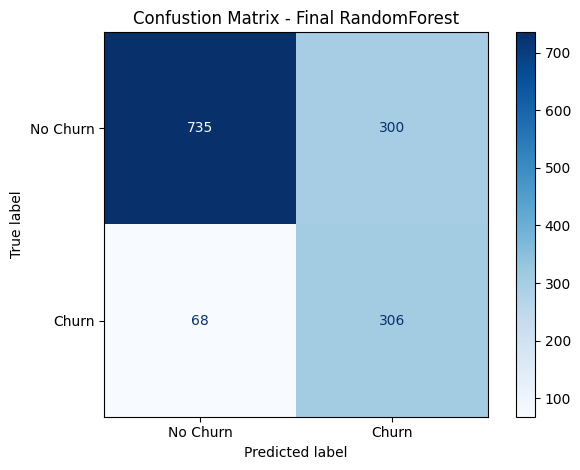

In [45]:
# Plot confusion matrix (default threshold)
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_default,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
fig_confusion_matrix = cm_display.figure_

plt.title("Confustion Matrix - Final RandomForest")
plt.tight_layout()
plt.show()

### 7.5 ROC Curve

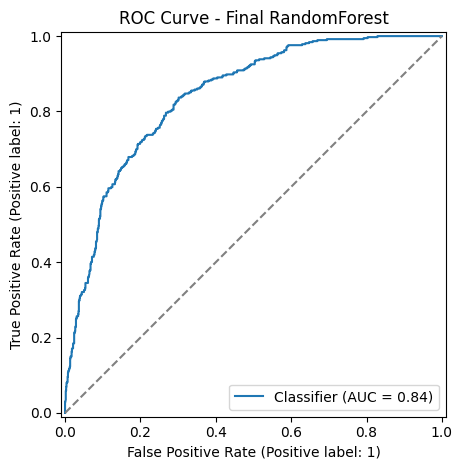

In [46]:
# Plot ROC curve
roc_display = RocCurveDisplay.from_predictions(y_test, y_test_proba)
fig_roc_curve = roc_display.figure_

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curve - Final RandomForest")
plt.tight_layout()
plt.show()

### 7.6 Classification Threshold Analysis

Earlier version of this sweep picked the threshold using `y_test_proba`
the same test set used for "final" evaluation. That's leakage: the
threshold ends up chosen based on the exact data it's later graded against.

Fixed here by sweeping thresholds against **out-of-fold predictions on the
training set** instead each row's probability comes from a fold it
wasn't trained on, so it behaves like unseen data without spending the
actual test set. `X_test` gets touched exactly once, after the threshold
is locked in.

In [47]:
# Out-of-fold probabilities from threshold selection.
# Test set is not used during threshold selection.
oof_model = RandomForestClassifier(
    random_state=42,
    n_jobs=1,
    **best_params
)

oof_probas = cross_val_predict(
    oof_model,
    X_train,
    y_train,
    cv=CV,
    method="predict_proba",
    n_jobs=N_JOBS
)[:, 1]

In [48]:
# Evaluate different classification thresholds using OOF predictions
thresholds = np.arange(0.30, 0.61, 0.01)

threshold_results = []
for threshold in thresholds:
    oof_pred = (oof_probas >= threshold).astype(int)
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_train, oof_pred),
        "Precision": precision_score(y_train, oof_pred, zero_division=0),
        "Recall": recall_score(y_train, oof_pred, zero_division=0),
        "F1": f1_score(y_train, oof_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,Threshold,Accuracy,Precision,Recall,F1
0,0.30,0.610046,0.400057,0.939799,0.561214
1,0.31,0.620341,0.406504,0.936455,0.566916
2,0.32,0.626553,0.410468,0.933779,0.570261
3,0.33,0.633120,0.414830,0.931773,0.574078
4,0.34,0.641285,0.420303,0.927759,0.578519
5,0.35,0.649095,0.425800,0.925084,0.583175
6,0.36,0.657082,0.431697,0.923746,0.588411
7,0.37,0.660454,0.433944,0.918395,0.589397
8,0.38,0.665779,0.437860,0.914381,0.592159
9,0.39,0.672879,0.443359,0.911037,0.596453


In [49]:
# Select thresholds that satisfy the minimum Recall requirement (still
# computed from OOF predictions not the test set)
candidate_thresholds = threshold_df[threshold_df["Recall"] >= 0.80].copy()
candidate_thresholds

,Threshold,Accuracy,Precision,Recall,F1
0,0.30,0.610046,0.400057,0.939799,0.561214
1,0.31,0.620341,0.406504,0.936455,0.566916
2,0.32,0.626553,0.410468,0.933779,0.570261
3,0.33,0.633120,0.414830,0.931773,0.574078
4,0.34,0.641285,0.420303,0.927759,0.578519
5,0.35,0.649095,0.425800,0.925084,0.583175
6,0.36,0.657082,0.431697,0.923746,0.588411
7,0.37,0.660454,0.433944,0.918395,0.589397
8,0.38,0.665779,0.437860,0.914381,0.592159
9,0.39,0.672879,0.443359,0.911037,0.596453


In [50]:
# Threshold that would be picked by the plain F1/Recall heuristic
# kept here for comparison against the cost-based pick in 7.6 below.
if candidate_thresholds.empty:
    best_threshold_row = threshold_df.loc[threshold_df["Recall"].idxmax()]
else:
    best_threshold_row = candidate_thresholds.loc[candidate_thresholds["F1"].idxmax()]

heuristic_threshold = float(best_threshold_row["Threshold"])

print("=" * 70)
print("F1/RECALL-HEURISTIC THRESHOLD (for comparison only)")
print("-" * 70)
print(f"Threshold: {heuristic_threshold:.2f}")
print(f"Accuracy: {best_threshold_row['Accuracy']:.4f}")
print(f"Precision: {best_threshold_row['Precision']:.4f}")
print(f"Recall: {best_threshold_row['Recall']:.4f}")
print(f"F1: {best_threshold_row['F1']:.4f}")
print("=" * 70)

F1/RECALL-HEURISTIC THRESHOLD (for comparison only)
----------------------------------------------------------------------
Threshold: 0.50
Accuracy: 0.7442
Precision: 0.5113
Recall: 0.8181
F1: 0.6293


In [51]:
# Metrics at the F1-heuristic threshold, for comparison only.
# The threshold that actually gets used going forward is chosen in 7.6.
y_pred_heuristic = (y_test_proba >= heuristic_threshold).astype(int)

heuristic_test_accuracy = accuracy_score(y_test, y_pred_heuristic)
heuristic_test_precision = precision_score(y_test, y_pred_heuristic, zero_division=0)
heuristic_test_recall = recall_score(y_test, y_pred_heuristic, zero_division=0)
heuristic_test_f1 = f1_score(y_test, y_pred_heuristic, zero_division=0)


print(f"Accuracy: {heuristic_test_accuracy:.4f}")
print(f"Precision: {heuristic_test_precision:.4f}")
print(f"Recall: {heuristic_test_recall:.4f}")
print(f"F1: {heuristic_test_f1:.4f}")


Accuracy: 0.7388
Precision: 0.5050
Recall: 0.8182
F1: 0.6245


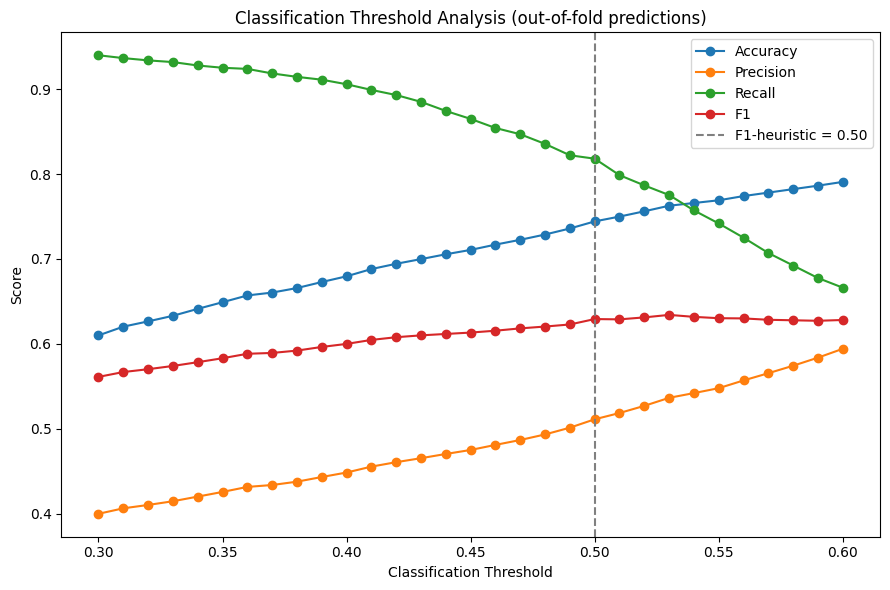

In [52]:
# Plot Accuracy, Precision, Recall and F1 across thresholds (OOF-based)
fig_threshold_analysis = plt.figure(figsize=(9, 6))

plt.plot(threshold_df["Threshold"], threshold_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"], marker="o", label="F1")
plt.axvline(heuristic_threshold, linestyle="--", color="gray",
            label=f"F1-heuristic = {heuristic_threshold:.2f}"
)

plt.title("Classification Threshold Analysis (out-of-fold predictions)")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()

plt.tight_layout()
plt.show()

### 7.7 Cost-Based Threshold Selection

The F1/Recall-heuristic threshold above is a reasonable starting point, but
"Recall matters more" doesn't say *how much* more. Putting a rough dollar
cost on each error type turns this into an actual optimization instead of
a judgment call:

- **False negative** (missed churner): lost revenue/CLV from a customer who
  leaves without ever being offered anything
- **False positive** (unnecessary offer): cost of a retention incentive
  given to someone who wasn't going to churn anyway

The numbers below are placeholders — swap them for whatever finance/product
actually estimates for average CLV and offer cost.

In [53]:
# Assign a rough cost to each error type placeholders replace with real figures
# assumed lost revenue/CLV per uncaught churner
COST_PER_MISSED_CHURN = 500
# assumed cost of a retention offer sent to a non-churner
COST_PER_UNNECESSARY_OFFER = 50
cost_results = []
for threshold in thresholds:
    oof_pred = (oof_probas >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, oof_pred).ravel()
    total_cost = fn * COST_PER_MISSED_CHURN + fp * COST_PER_UNNECESSARY_OFFER
    cost_results.append({
        "threshold": round(threshold, 2),
        "FN": fn,
        "FP": fp,
        "Total_Cost": total_cost
    })

cost_df = pd.DataFrame(cost_results)
cost_df

,threshold,FN,FP,Total_Cost
0,0.30,90,2107,150350
1,0.31,95,2044,149700
2,0.32,99,2005,149750
3,0.33,102,1965,149250
4,0.34,108,1913,149650
5,0.35,112,1865,149250
6,0.36,114,1818,147900
7,0.37,122,1791,150550
8,0.38,128,1755,151750
9,0.39,133,1710,152000


In [54]:
# Pick the threshold that minimized total expected cost
best_cost_row = cost_df.loc[cost_df["Total_Cost"].idxmin()]
best_threshold = float(best_cost_row["threshold"])

print("=" * 70)
print("COST-MINIMIZING THRESHOLD (this is what gets used going forward)")
print("-" * 70)
print(f"Threshold: {best_threshold:.2f}")
print(f"FN at this threshold: {int(best_cost_row['FN'])}")
print(f"FP at this threshold: {int(best_cost_row['FP'])}")
print(f"Total estimated cost: {best_cost_row['Total_Cost']:.0f}")
print("-" * 70)
print(f"For comparison, the F1-heuristic threshold was {heuristic_threshold:.2f}")
print("=" * 70)

COST-MINIMIZING THRESHOLD (this is what gets used going forward)
----------------------------------------------------------------------
Threshold: 0.36
FN at this threshold: 114
FP at this threshold: 1818
Total estimated cost: 147900
----------------------------------------------------------------------
For comparison, the F1-heuristic threshold was 0.50


In [55]:
# Recompute final metrics AT the cost-minimizing threshold — the ONE time
# X_test gets used to pick a number we report. best_threshold was chosen
# entirely from out-of-fold training data above, never from X_test.
y_pred_final = (y_test_proba >= best_threshold).astype(int)

final_test_accuracy = accuracy_score(y_test, y_pred_final)
final_test_precision = precision_score(y_test, y_pred_final, zero_division=0)
final_test_recall = recall_score(y_test, y_pred_final, zero_division=0)
final_test_f1 = f1_score(y_test, y_pred_final, zero_division=0)
final_test_roc_auc = test_roc_auc
final_test_pr_auc = average_precision_score(y_test, y_test_proba)

print(f"Accuracy: {final_test_accuracy:.4f}")
print(f"Precision: {final_test_precision:.4f}")
print(f"Recall: {final_test_recall:.4f}")
print(f"F1: {final_test_f1:.4f}")
print(f"ROC-AUC: {final_test_roc_auc:.4f}")
print(f"PR-AUC: {final_test_pr_auc:.4f}")

Accuracy: 0.6473
Precision: 0.4226
Recall: 0.8984
F1: 0.5749
ROC-AUC: 0.8415
PR-AUC: 0.6458


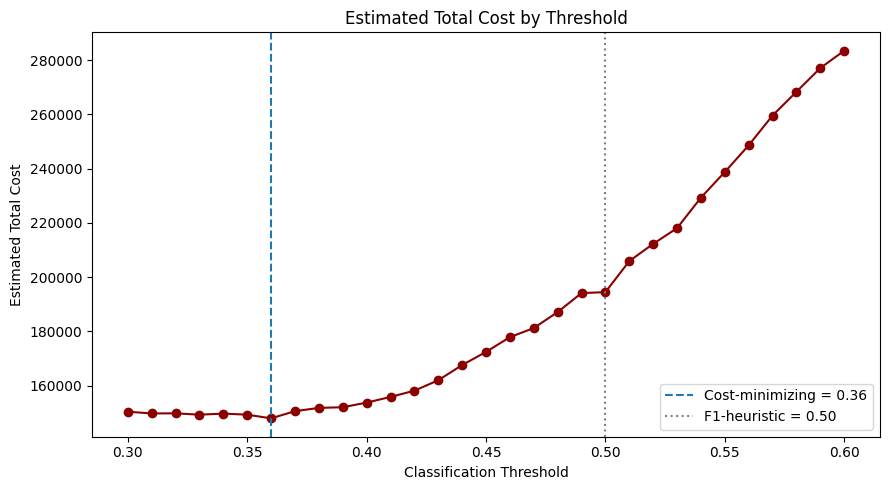

In [56]:
# Plot total cost across thresholds
fig_cost_analysis = plt.figure(figsize=(9, 5))

plt.plot(
    cost_df["threshold"],
    cost_df["Total_Cost"],
    marker="o",
    color="darkred"
)
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Cost-minimizing = {best_threshold:.2f}"
)
plt.axvline(
    heuristic_threshold,
    linestyle=":",
    color="gray",
    label=f"F1-heuristic = {heuristic_threshold:.2f}"
)

plt.title("Estimated Total Cost by Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("Estimated Total Cost")
plt.legend()

plt.tight_layout()
plt.show()

### 7.8 Feature Importance

In [57]:
# Calculate permutation importance using Recall
perm_importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="recall",
    n_repeats=10,
    random_state=42,
    n_jobs=N_JOBS
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean
})

importance_df = importance_df.sort_values("Importance", ascending=False).head(15)
importance_df

,Feature,Importance
25,Contract_Two year,0.103743
1,tenure,0.064706
10,InternetService_Fiber optic,0.056417
2,MonthlyCharges,0.027005
3,TotalCharges,0.021925
28,PaymentMethod_Electronic check,0.016845
16,DeviceProtection_No internet service,0.013369
22,StreamingMovies_No internet service,0.009893
29,PaymentMethod_Mailed check,0.009626
20,StreamingTV_No internet service,0.009358


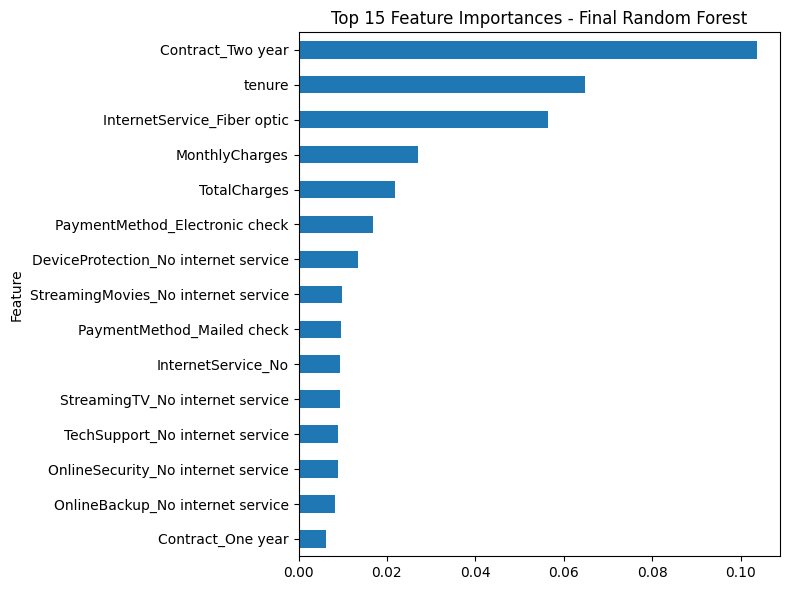

In [58]:
# Plot the top 15 features
fig_feature_importance = plt.figure(figsize=(8, 6))

importance_df.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    ax=plt.gca()
)

plt.title("Top 15 Feature Importances - Final Random Forest")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 7.9 Error Analysis

Confusion matrix says *how many* mistakes; this looks at *what kind*. If
false negatives all share some trait the model isn't using well, that's a
lead for feature engineering — more useful than just re-tuning the same
features harder.

In [59]:
# Pull out the false negatives / false positives on the test set and look
# at what makes them different from the rest of the population. This is
# post-hoc inspection, not threshold selection, so looking at X_test here
# doesn't reintrode the leakage problem from 7.5.
errors_df = X_test.copy()
errors_df["y_true"] = y_test.values
errors_df["y_pred"] = y_pred_final
errors_df["y_proba"] = y_test_proba

false_negatives = errors_df[(errors_df["y_true"] == 1) & (errors_df["y_pred"] == 0)]
false_positives = errors_df[(errors_df["y_true"] == 0) & (errors_df["y_pred"] == 1)]

print(f"False negatives (missed churners): {len(false_negatives)}")
print(f"False positives (unnecessary flags): {len(false_positives)}")

False negatives (missed churners): 38
False positives (unnecessary flags): 459


In [60]:
# Compare tenure, MonthlyCharges and TotalCharges for each error group against the
# overall test set — looking for a pattern the model is missing
comparison_features = ["tenure", "MonthlyCharges", "TotalCharges"]

error_comparison = pd.concat({
    "Mean": pd.DataFrame({
        "Overall Test": X_test[comparison_features].mean(),
        "False Negatives": false_negatives[comparison_features].mean(),
        "False Positives": false_positives[comparison_features].mean()
    }),
    "Median (50%)": pd.DataFrame({
        "Overall Test": X_test[comparison_features].median(),
        "False Negatives": false_negatives[comparison_features].median(),
        "False Positives": false_positives[comparison_features].median()
    })
})

error_comparison.round(4)

Overall Test  False Negatives  False Positives
Mean         tenure               31.9155          34.1316          25.5207
             MonthlyCharges       64.0889          55.6776          74.0321
             TotalCharges       2204.3361        2550.3645        2185.3167
Median (50%) tenure               28.0000          37.0000          21.0000
             MonthlyCharges       69.9500          56.4000          78.7500
             TotalCharges       1397.4750        2113.9750        1468.7500

In [61]:
# Save the error rows themselves for closer inspection ouside this notebook
log_dataframe_artifact(false_negatives, "false_negatives")
log_dataframe_artifact(false_positives, "false_positives")

print("False Negative / False Positive rows saved for the MLflow logging.")

False Negative / False Positive rows saved for the MLflow logging.


### Observation

The final test results contains 38 false negatives and 459 false positives. The model misses relatively few actual churn customers but it also flags many non-churning customers because the model was tuned to achieve high Recall.

## 8. MLflow Experiment Tracking

### 8.1 Final Model Logging

In [63]:
# Close any active MLflow run before starting the final model run
if mlflow.active_run() is not None:
    mlflow.end_run()

# Infer the model input and output signature
signature = infer_signature(X_train, y_train_pred)

# Log the final model, its metrics and the evaluation charts to MLflow
with mlflow.start_run(run_name="best_model_experiment"):

    # Log model and experiment configuration
    mlflow.log_param("model", best_model_name)
    mlflow.log_param("optimization_method", search_method)
    mlflow.log_param("cv_strategy","StratifiedKFold")
    mlflow.log_param("cv_folds", CV_FOLDS)
    mlflow.log_param("scoring", "recall")
    mlflow.log_param("classification_threshold", best_threshold)
    mlflow.log_param("threshold_selection_method", "cost_minimizing")
    mlflow.log_param("f1_heuristic_threshold", heuristic_threshold)
    mlflow.log_param("cost_per_missed_churn", COST_PER_MISSED_CHURN)
    mlflow.log_param("cost_per_unnecessary_offer", COST_PER_UNNECESSARY_OFFER)
    mlflow.log_params(best_params)

    # Cross-validation result
    mlflow.log_metric("CV_Recall", best_cv_recall)

    # Train metrics
    mlflow.log_metric("Train_Accuracy", train_accuracy)
    mlflow.log_metric("Train_Precision", train_precision)
    mlflow.log_metric("Train_Recall", train_recall)
    mlflow.log_metric("Train_F1", train_f1)

    # Test metrics
    mlflow.log_metric("Test_Accuracy", final_test_accuracy)
    mlflow.log_metric("test_precision", final_test_precision)
    mlflow.log_metric("Test_Recall", final_test_recall)
    mlflow.log_metric("Test_F1", final_test_f1)
    mlflow.log_metric("Test_ROC_AUC", final_test_roc_auc)
    mlflow.log_metric("Test_PR_AUC", final_test_pr_auc)
    mlflow.log_metric("Estimated_Total_Cost", best_cost_row["Total_Cost"])

    # Overfitting check
    mlflow.log_metric("Recall_Gap", train_recall - final_test_recall)

    # Evaluation charts
    log_matplotlib_figure(fig_confusion_matrix, "confusion_matrix")
    log_matplotlib_figure(fig_roc_curve, "roc_curve")
    log_matplotlib_figure(fig_threshold_analysis, "threshold_analysis")
    log_matplotlib_figure(fig_cost_analysis, "cost_analysis")
    log_matplotlib_figure(fig_feature_importance, "feature_importance")

    # Supporting tables
    log_dataframe_artifact(threshold_df, "threshold_sweep_oof")
    log_dataframe_artifact(cost_df, "cost_sweep_oof")
    log_dataframe_artifact(importance_df, "feature_importance")
    mlflow.log_text(classification_report_default, "classification_report_default_threshold.txt")

    # Final model artifact with signature and input example
    mlflow.sklearn.log_model(
        best_model,
        "model",
        signature=signature,
        input_example=X_train.head()
    )

print("Final model, metrics and evaluation visuals logged to MLflow/DagsHub.")

2026/09/28 13:19:31 INFO mlflow.tracking._tracking_service.client: 🏃 View run chill-owl-642 at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0/runs/f764ef2c4d664626973f2e6e6d6e4e1b.
2026/09/28 13:19:31 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0.


2026/09/28 13:20:20 INFO mlflow.tracking._tracking_service.client: 🏃 View run best_model_experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0/runs/2302344dcf244e189567fc4288c237b6.
2026/09/28 13:20:20 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/TechArif/customer-churn-prediction-system.mlflow/#/experiments/0.


Final model, metrics and evaluation visuals logged to MLflow/DagsHub.


## 9. Conclusion

RandomForest ended up being the final model, and Optuna found a slightly better configuration than RandomizedSearchCV (0.8181 vs. 0.8100 recall). For threshold selection, we used out-of-fold predictions instead of the test set to avoid tuning the cutoff on the data used for final evaluation. The final threshold was selected by minimizing the estimated cost of missed churns and unnecessary offers, with the cost values treated as placeholders for now.

Everything is logged to MLflow on DagsHub, including the final model, parameters, metrics, threshold analysis, and evaluation artifacts.
